# Chirp-z transform: zoomed spectra, shifted and scaled propagation

An FFT evaluates a Fourier sum on one fixed grid: $N$ frequencies with the
spacing $2\pi/L$. Often only a small part of that grid is of interest, but
with a finer sampling: the core of a PSF, one diffraction order, an off-axis
detector. Zero padding gets there at the cost of huge arrays.
The **chirp-z transform** (Bluestein 1970) evaluates

$$ X_m = \sum_{n=0}^{N-1} x_n\, a^{-n} w^{nm}, \qquad m = 0, \dots, M-1, $$

for *any* start $a$ and step $w$ with three FFTs of length $\geq N + M - 1$.
With $a = e^{i k_0 \Delta x}$, $w = e^{-i \Delta k \Delta x}$ it is a Fourier
sum on the frequencies $k_0 + m\,\Delta k$ with free $k_0$, $\Delta k$ and $M$.

| Function | What it does |
|---|---|
| `fft.czt(x, M, w, a)` | Bluestein's chirp-z transform (any axis) |
| `fft.zoom_FT(f, x, y, kx_out, ky_out)` | `FT()` on any equidistant frequency grid |
| `fft.zoom_inv_FT(F, kx, ky, x_out, y_out)` | `inv_FT()` on any equidistant grid of positions |
| `propagators.shifted_angular_spectrum()` | exact propagation onto an off-axis, rescaled window (Matsushima 2010) |
| `propagators.fresnel_scaled()` | Fresnel integral onto any window |
| `propagators.fraunhofer_scaled()` | Fraunhofer integral onto any window |
| `propagators.far_field()` | far field amplitude in chosen directions |
| `imaging.get_psf(..., x_out, y_out)` | PSF on any window without padding |

All of them keep the pyoptics conventions: fields vary as
$\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$, `FT()` has the kernel
$e^{-i\mathbf{k}\cdot\mathbf{r}}$ and returns plane wave amplitudes. Lengths
are in units of the wavelength.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pyoptics.fft import FT, czt, zoom_FT, zoom_inv_FT
from pyoptics.utils import grid1d, frequencies, pad
from pyoptics.analytical import airy_pattern
from pyoptics.imaging import get_psf
from pyoptics.propagators import (rayleigh_sommerfeld_I_TF, shifted_angular_spectrum,
                                  fresnel_scaled, fresnel_rescaling, far_field)

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})
WL = 1.0
K = 2*np.pi/WL

## 1. The chirp-z transform is a DFT on any frequency grid

First a check against the definition: for $a = 1$, $w = e^{-2\pi i/N}$,
$M = N$ the chirp-z transform is the DFT, and for any other $a$, $w$ it
equals the direct sum (here for a random signal; the error is round-off).

In [2]:
rng = np.random.default_rng(0)
x = rng.normal(size=300) + 1j*rng.normal(size=300)
X_fft = np.fft.fft(x)
print("czt vs. np.fft.fft:  max relative error {:.1e}".format(np.abs(czt(x) - X_fft).max()/np.abs(X_fft).max()))

M, w, a = 400, np.exp(-0.0071j), np.exp(0.83j)
n, m = np.arange(len(x)), np.arange(M)
direct = (x[None, :]*a**(-n[None, :])*w**(n[None, :]*m[:, None])).sum(axis=1)
print("czt vs. direct sum: max relative error {:.1e}".format(np.abs(czt(x, M, w, a) - direct).max()/np.abs(direct).max()))

czt vs. np.fft.fft:  max relative error 5.5e-13
czt vs. direct sum: max relative error 4.1e-14


`zoom_FT()` uses this to evaluate the spectrum of a field on a frequency
grid of our choice. The example is a 1D slit of width $10\lambda$ sampled on
$N = 64$ points: the FFT gives the spectrum only at the multiples of
$2\pi/L$ (dots); `zoom_FT()` gives it on a 20× finer grid over the central
lobes (line), which is the same as the FFT of the 20× zero padded field, but
uses arrays of length $\approx N + M$ instead of $20N$. The analytic spectrum
of the sampled slit (a Dirichlet kernel) lies on top.

max deviation from the analytic sum: 9.0e-13


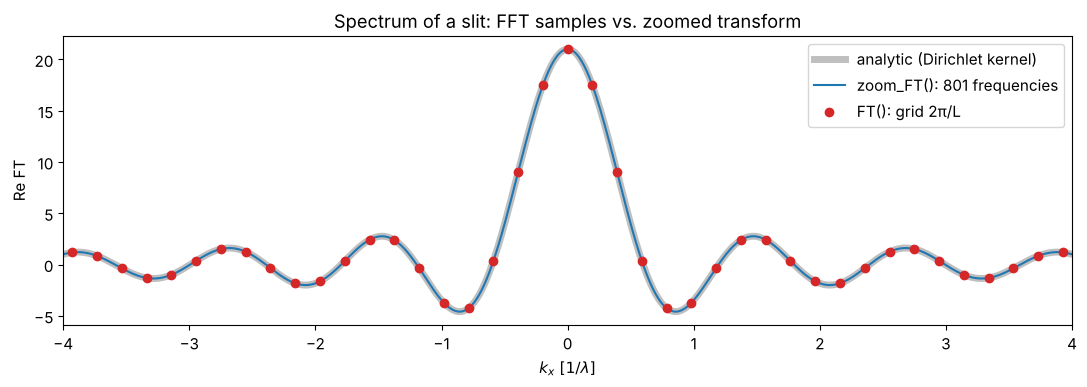

In [3]:
L, N = 32.0, 64
x = grid1d(-L/2, L/2, N)
f = (np.abs(x) <= 5.0).astype(complex)[None, :]          # 1 x N "image"
kx = frequencies(x)

kx_fine = np.linspace(-4, 4, 801)
F_zoom = zoom_FT(f, x, np.array([0.0]), kx_fine, np.array([0.0]))[0]
F_fft = FT(f)[0]

dx = x[1] - x[0]
n_open = np.count_nonzero(np.abs(x) <= 5.0)                 # 21 open samples, centered
with np.errstate(invalid="ignore", divide="ignore"):
    dirichlet = np.where(np.isclose(np.sin(kx_fine*dx/2), 0), n_open,
                         np.sin(n_open*kx_fine*dx/2)/np.sin(kx_fine*dx/2))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(kx_fine, dirichlet, color="0.75", lw=5, label="analytic (Dirichlet kernel)")
ax.plot(kx_fine, F_zoom.real, "C0", lw=1.5, label="zoom_FT(): 801 frequencies")
ax.plot(kx, F_fft.real, "o", color="C3", ms=6, label="FT(): grid 2π/L")
ax.set_xlim(-4, 4)
ax.set_xlabel(r"$k_x\ [1/\lambda]$"); ax.set_ylabel("Re FT")
ax.legend(); ax.set_title("Spectrum of a slit: FFT samples vs. zoomed transform")
plt.tight_layout()
print("max deviation from the analytic sum: {:.1e}".format(np.abs(F_zoom - dirichlet).max()))

How much does zooming save? The table compares `zoom_FT()` onto a $256^2$
window with the zero-padded FFT that gives the same frequency spacing
(zoom factor $Z$: the padded field has $(ZN)^2$ samples, of which we only need
a small part).

In [4]:
N = 256
x = grid1d(-64, 64, N)
X, Y = np.meshgrid(x, x)
f = np.exp(-(X**2 + Y**2)/10.0**2).astype(complex)
dk = 2*np.pi/(x[-1] - x[0] + x[1] - x[0])
print(" zoom    padded FFT [s]   zoom_FT [s]   max difference")
for Z in (4, 8, 16):
    t0 = time.perf_counter()
    f_pad, x_pad, _ = pad(f, x, x, factor=Z)
    F_pad = FT(f_pad)
    k_pad = frequencies(x_pad)
    t_pad = time.perf_counter() - t0
    sl = slice(Z*N//2 - 128, Z*N//2 + 128)
    t0 = time.perf_counter()
    F_zoom = zoom_FT(f, x, x, k_pad[sl], k_pad[sl])
    t_zoom = time.perf_counter() - t0
    print("{:4d}    {:12.3f}   {:10.3f}     {:.1e}".format(Z, t_pad, t_zoom, np.abs(F_zoom - F_pad[sl, sl]).max()/np.abs(F_pad).max()))

 zoom    padded FFT [s]   zoom_FT [s]   max difference


   4           0.301        0.012     1.1e-12


   8           0.971        0.011     6.5e-13


  16           3.979        0.009     1.0e-12


## 2. Zooming into the PSF

`imaging.get_psf()` samples the pupil on the frequency grid of the image
plane grid `x, y`; the image grid therefore has to be large to sample the
pupil well, and fine to resolve the PSF – usually conflicting wishes. With
`x_out, y_out` the PSF is evaluated by a chirp-z transform of the pupil on
any window: `x, y` only set the pupil sampling.

Here the image grid has $256^2$ points with $\Delta x = 0.39\lambda$ (a
pupil radius of 50 samples at NA 0.5); the zoomed PSF is evaluated on a
$\lambda/100$ grid over the Airy disk. Its cut agrees with the analytic Airy
pattern to the accuracy of the pupil sampling.

max deviation from Airy: 4.3e-04


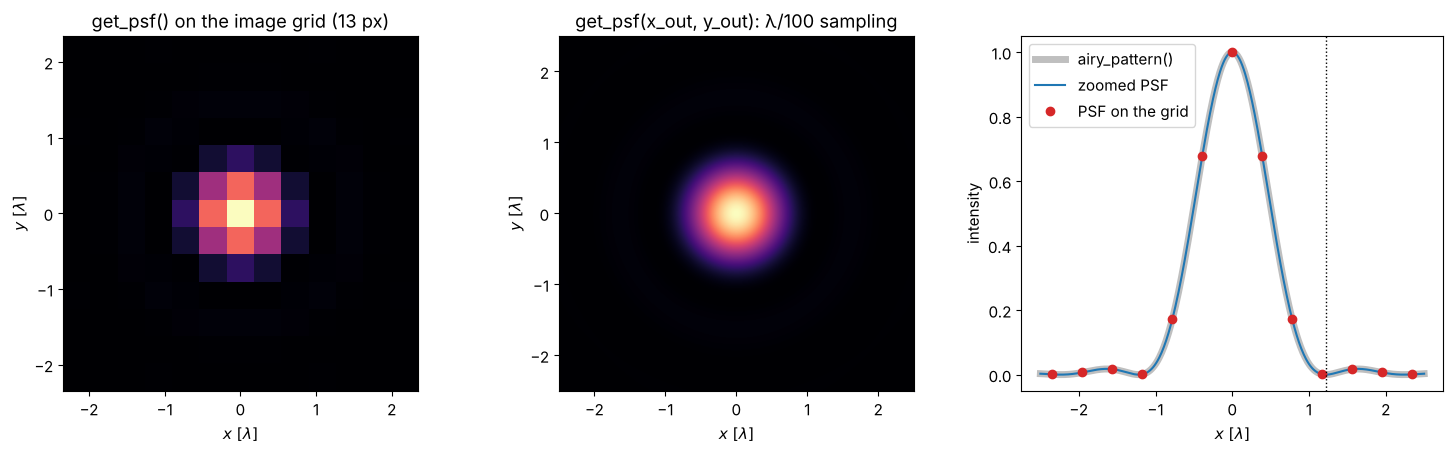

In [5]:
NA = 0.5
L, N = 100*WL, 256
x = grid1d(-L/2, L/2, N)
x_out = np.linspace(-2.5, 2.5, 501)

psf_grid = get_psf(x, x, NA, K)
psf_zoom = get_psf(x, x, NA, K, x_out=x_out, y_out=x_out)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ext = [x[0], x[-1], x[0], x[-1]]
sel = np.abs(x) <= 2.5
axes[0].imshow(np.abs(psf_grid[np.ix_(sel, sel)])**2, extent=[x[sel][0], x[sel][-1]]*2, cmap="magma")
axes[0].set_title("get_psf() on the image grid ({} px)".format(np.count_nonzero(sel)))
axes[1].imshow(np.abs(psf_zoom)**2, extent=[x_out[0], x_out[-1]]*2, cmap="magma")
axes[1].set_title("get_psf(x_out, y_out): λ/100 sampling")
for ax in axes[:2]:
    ax.set_xlabel(r"$x\ [\lambda]$"); ax.set_ylabel(r"$y\ [\lambda]$")

I_cut = np.abs(psf_zoom[250])**2
axes[2].plot(x_out, airy_pattern(np.abs(x_out), NA, WL), color="0.75", lw=5, label="airy_pattern()")
axes[2].plot(x_out, I_cut, "C0", label="zoomed PSF")
axes[2].plot(x[sel], np.abs(psf_grid[N//2, sel])**2, "o", color="C3", label="PSF on the grid")
axes[2].axvline(0.61*WL/NA, color="k", ls=":", lw=1)
axes[2].set_xlabel(r"$x\ [\lambda]$"); axes[2].set_ylabel("intensity")
axes[2].legend()
plt.tight_layout()
print("max deviation from Airy: {:.1e}".format(np.abs(I_cut - airy_pattern(np.abs(x_out), NA, WL)).max()))

The output window can be placed anywhere, e.g. on the comatic flare of an
aberrated PSF. The PSF of the discrete pupil is periodic with the image
window $L$; within it, every window is exact.

Strehl ratio from the zoomed PSF (peak value): 0.446


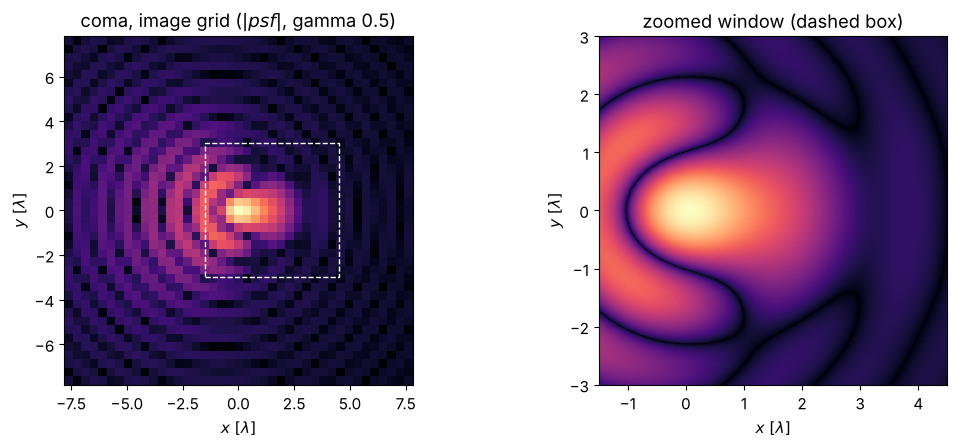

In [6]:
coma = lambda P_x, P_y: 2*np.pi*0.4*(3*(P_x**2 + P_y**2) - 2)*P_x   # 0.4 waves Fringe Z7
psf_coma = get_psf(x, x, NA, K, phase=coma)
x_win, y_win = np.linspace(-1.5, 4.5, 301), np.linspace(-3, 3, 301)
psf_win = get_psf(x, x, NA, K, phase=coma, x_out=x_win, y_out=y_win)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
sel = np.abs(x) <= 8
axes[0].imshow(np.abs(psf_coma[np.ix_(sel, sel)])**0.5, extent=[x[sel][0], x[sel][-1]]*2, cmap="magma")
axes[0].add_patch(plt.Rectangle((x_win[0], y_win[0]), 6, 6, fill=False, ec="w", ls="--"))
axes[0].set_title(r"coma, image grid ($|psf|$, gamma 0.5)")
axes[1].imshow(np.abs(psf_win)**0.5, extent=[x_win[0], x_win[-1], y_win[0], y_win[-1]], cmap="magma")
axes[1].set_title("zoomed window (dashed box)")
for ax in axes:
    ax.set_xlabel(r"$x\ [\lambda]$"); ax.set_ylabel(r"$y\ [\lambda]$")
plt.tight_layout()
print("Strehl ratio from the zoomed PSF (peak value): {:.3f}".format(np.max(np.abs(psf_win))**2))

## 3. The focus of a lens with `fresnel_scaled()`

`fresnel_scaled()` evaluates the single-transform Fresnel integral

$$ U(x, y) = \frac{e^{ikz}}{i\lambda z} e^{ik(x^2+y^2)/2z}
\iint U'(x', y')\, e^{ik(x'^2+y'^2)/2z}\, e^{-ik(xx' + yy')/z}\,dx'\,dy' $$

with `zoom_FT()` at $k_x = kx/z$. `fresnel_rescaling()` evaluates the same
integral by FFT, but its output spacing is fixed to $\lambda z/L$ – at the
focus of a lens usually far too coarse. Here a lens with $f = 2000\lambda$
and an aperture of $D = 200\lambda$ ($\mathrm{NA} \approx 0.05$, Airy radius
$12\lambda$) is sampled with $512^2$ points; `fresnel_rescaling()` puts only
about 2 samples into the Airy disk.

first zero: fresnel_scaled() 12.25λ, Airy 0.61λ/NA = 12.20λ


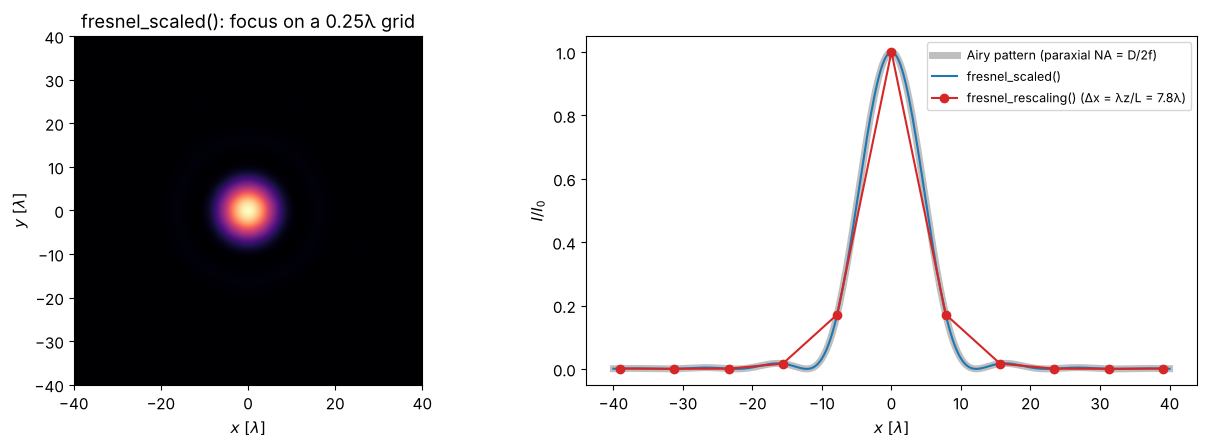

In [7]:
f_lens, D = 2000.0, 200.0
L, N = 256.0, 512
x = grid1d(-L/2, L/2, N)
X, Y = np.meshgrid(x, x)
pupil = (X**2 + Y**2 <= (D/2)**2)*np.exp(-1j*K*(X**2 + Y**2)/(2*f_lens))

U_resc, x_resc, y_resc = fresnel_rescaling(pupil, x, x, f_lens, WL)
x_out = np.linspace(-40, 40, 321)
U_zoom, _, _ = fresnel_scaled(pupil, x, x, f_lens, WL, x_out, x_out)

NA_lens = np.sin(np.arctan(D/2/f_lens))
I0 = np.abs(U_zoom[160, 160])**2
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].imshow(np.abs(U_zoom)**2/I0, extent=[x_out[0], x_out[-1]]*2, cmap="magma", vmax=1)
axes[0].set_title("fresnel_scaled(): focus on a 0.25λ grid")
axes[0].set_xlabel(r"$x\ [\lambda]$"); axes[0].set_ylabel(r"$y\ [\lambda]$")
sel = np.abs(x_resc) <= 40
axes[1].plot(x_out, airy_pattern(np.abs(x_out), D/2/f_lens, WL), color="0.75", lw=5, label="Airy pattern (paraxial NA = D/2f)")
axes[1].plot(x_out, np.abs(U_zoom[160])**2/I0, "C0", label="fresnel_scaled()")
axes[1].plot(x_resc[sel], np.abs(U_resc[N//2, sel])**2/I0, "o-", color="C3", label="fresnel_rescaling() (Δx = λz/L = {:.1f}λ)".format(x_resc[1] - x_resc[0]))
axes[1].set_xlabel(r"$x\ [\lambda]$"); axes[1].set_ylabel(r"$I/I_0$"); axes[1].legend(fontsize=9)
plt.tight_layout()
print("first zero: fresnel_scaled() {:.2f}λ, Airy 0.61λ/NA = {:.2f}λ".format(
    x_out[160 + np.argmin(np.abs(U_zoom[160, 160:240]))], 0.61*WL*2*f_lens/D))

Two sampling conditions remain, and `fresnel_scaled()` warns about both: the
input chirp $e^{ikr'^2/2z}$ must be sampled on the input grid
($|z| \gtrsim 2\max|x'|\Delta x/\lambda$; above, the lens phase cancels most
of it), and the result is periodic with $\lambda z/\Delta x$, so the output
window should be smaller than that. For short distances the angular
spectrum is the right tool.

## 4. Off-axis propagation with the shifted angular spectrum method

A Gaussian beam ($w_0 = 5\lambda$) is tilted by 20° and propagates by
$z = 200\lambda$: it arrives about $73\lambda$ off axis, far outside the input
window of $64\lambda$. The ordinary angular spectrum method needs a window
that holds both the source and the detector. `shifted_angular_spectrum()`
evaluates

$$ U(x, y, z) = \frac{1}{N_xN_y}\sum_{mn} A_{mn}\, e^{i(k_x x + k_y y + k_z z)} $$

directly on the detector window with `zoom_inv_FT()`. The input is padded to
the size of source plus detector window, and only plane waves that travel
from the source window into the detector window are kept, i.e. the lateral
shift $z\,k_x/k_z$ lies between $\min x_\mathrm{out} - \max x'$ and
$\max x_\mathrm{out} - \min x'$ (Matsushima's band limit). The reference is
an angular spectrum computation on a $16\times$ larger window.

reference (2048² ASM): 3.36 s, shifted ASM: 0.019 s
max error shifted ASM: 5.4e-07; without padding and band limit: 2.8e-02


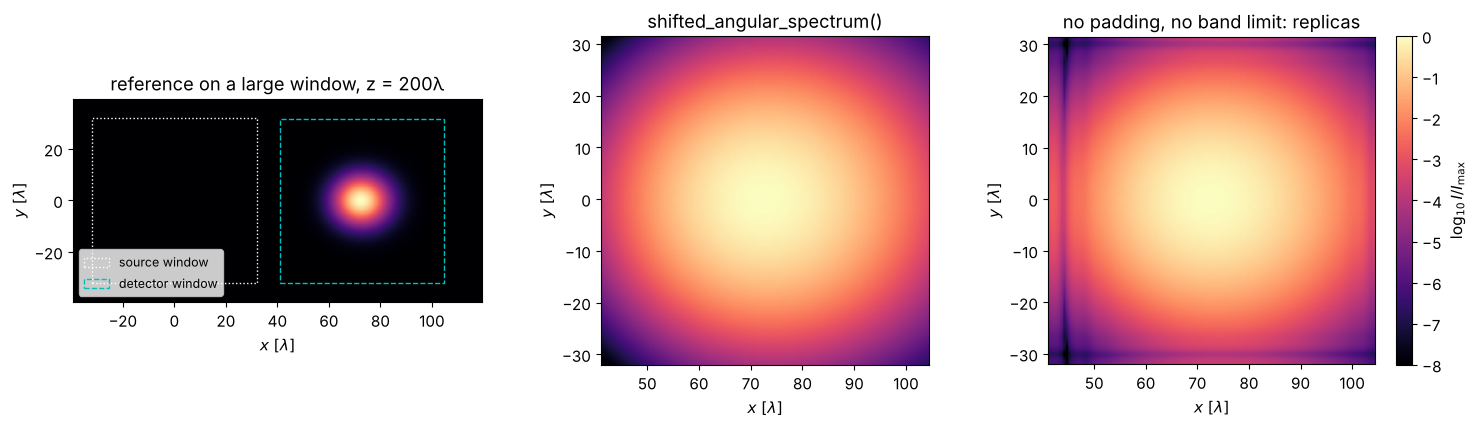

In [8]:
L, N, z, theta, w0 = 64.0, 128, 200.0, np.deg2rad(20), 5.0
x = grid1d(-L/2, L/2, N)
X, Y = np.meshgrid(x, x)
source = np.exp(-(X**2 + Y**2)/w0**2)*np.exp(1j*K*np.sin(theta)*X)

# reference: large window
N_ref = 2048
f_ref, x_ref, _ = pad(source, x, x, shape=(N_ref, N_ref))
t0 = time.perf_counter()
U_ref, _, _ = rayleigh_sommerfeld_I_TF(f_ref, x_ref, x_ref, z, WL)
t_ref = time.perf_counter() - t0

x0 = z*np.tan(theta)
i0 = np.argmin(np.abs(x_ref - x0))
rows, cols = slice(N_ref//2 - 64, N_ref//2 + 64), slice(i0 - 64, i0 + 64)
x_det, y_det = x_ref[cols], x_ref[rows]

t0 = time.perf_counter()
U_sas, _, _ = shifted_angular_spectrum(source, x, x, z, WL, x_det, y_det)
t_sas = time.perf_counter() - t0
U_alias, _, _ = shifted_angular_spectrum(source, x, x, z, WL, x_det, y_det, band_limit=False, pad_factor=1)

err = np.abs(U_sas - U_ref[rows, cols]).max()/np.abs(U_ref[rows, cols]).max()
err_alias = np.abs(U_alias - U_ref[rows, cols]).max()/np.abs(U_ref[rows, cols]).max()
print("reference ({}² ASM): {:.2f} s, shifted ASM: {:.3f} s".format(N_ref, t_ref, t_sas))
print("max error shifted ASM: {:.1e}; without padding and band limit: {:.1e}".format(err, err_alias))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
I_ref = np.abs(U_ref)**2
sel_x = (x_ref > -40) & (x_ref < 120); sel_y = np.abs(x_ref) < 40
axes[0].imshow(I_ref[np.ix_(sel_y, sel_x)], extent=[x_ref[sel_x][0], x_ref[sel_x][-1], x_ref[sel_y][0], x_ref[sel_y][-1]], cmap="magma")
axes[0].add_patch(plt.Rectangle((x[0], x[0]), L, L, fill=False, ec="w", ls=":", label="source window"))
axes[0].add_patch(plt.Rectangle((x_det[0], y_det[0]), x_det[-1] - x_det[0], y_det[-1] - y_det[0], fill=False, ec="c", ls="--", label="detector window"))
axes[0].legend(loc="lower left", fontsize=9)
axes[0].set_title("reference on a large window, z = 200λ")
I_peak = np.abs(U_sas).max()**2
for ax, U, title in ((axes[1], U_sas, "shifted_angular_spectrum()"),
                     (axes[2], U_alias, "no padding, no band limit: replicas")):
    im = ax.imshow(np.log10(np.abs(U)**2/I_peak + 1E-12), extent=[x_det[0], x_det[-1], y_det[0], y_det[-1]],
                   cmap="magma", vmin=-8, vmax=0)
    ax.set_title(title)
plt.colorbar(im, ax=axes[2], label=r"$\log_{10} I/I_\mathrm{max}$")
for ax in axes:
    ax.set_xlabel(r"$x\ [\lambda]$"); ax.set_ylabel(r"$y\ [\lambda]$")
plt.tight_layout()

The detector window can also have its own sampling. Below the detector is
sampled 4× finer than the source over a $20\lambda$ wide region around the
beam center; the phase shows the tilt and the curvature of the beam
($w \approx 21\lambda$ at this distance).

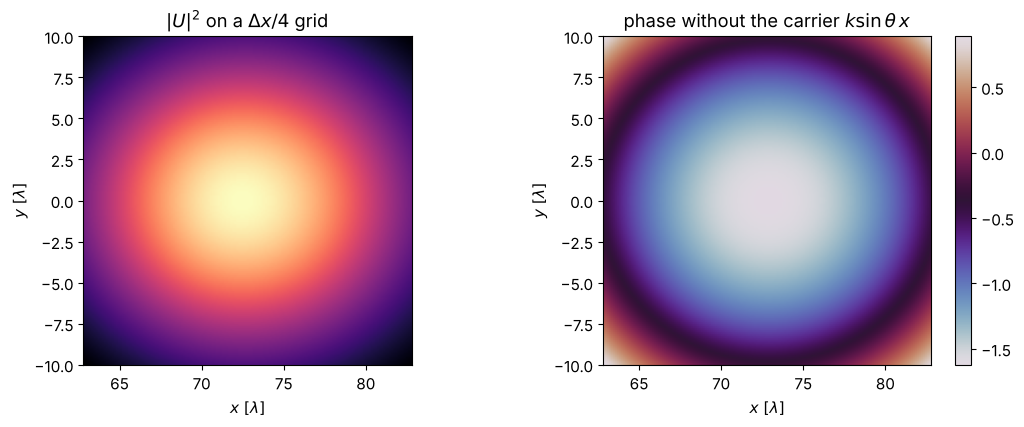

In [9]:
x_fine = np.linspace(x0 - 10, x0 + 10, 161)
y_fine = np.linspace(-10, 10, 161)
U_fine, _, _ = shifted_angular_spectrum(source, x, x, z, WL, x_fine, y_fine)
k_carrier = K*np.sin(theta)
X_f, Y_f = np.meshgrid(x_fine, y_fine)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].imshow(np.abs(U_fine)**2, extent=[x_fine[0], x_fine[-1], y_fine[0], y_fine[-1]], cmap="magma")
axes[0].set_title(r"$|U|^2$ on a $\Delta x/4$ grid")
im = axes[1].imshow(np.angle(U_fine*np.exp(-1j*k_carrier*X_f)), extent=[x_fine[0], x_fine[-1], y_fine[0], y_fine[-1]], cmap="twilight")
axes[1].set_title(r"phase without the carrier $k\sin\theta\,x$")
plt.colorbar(im, ax=axes[1])
for ax in axes:
    ax.set_xlabel(r"$x\ [\lambda]$"); ax.set_ylabel(r"$y\ [\lambda]$")
plt.tight_layout()

The band limit is what keeps the result free of replicas, but it depends
on the spectral spacing $2\pi/L_\mathrm{pad}$: the band of allowed directions
narrows as $(L_\mathrm{in} + L_\mathrm{out})/z$, and once it holds only a few
frequency samples, the angular spectrum method is the wrong tool (the
function warns). In that regime – the far field of the source – use
`fresnel_scaled()` or `far_field()`.

## 5. Far field at chosen angles: zooming into a diffraction order

`far_field()` returns the far field amplitude $f(\mathbf{s})$ with
$U(r\mathbf{s}) \to f(\mathbf{s})\,e^{ikr}/r$ for $r \to \infty$,

$$ f(\mathbf{s}) = \frac{k\sigma_z}{2\pi i} \iint U'(x', y')\,
e^{-ik(\sigma_x x' + \sigma_y y')}\,dx'\,dy', $$

on an equidistant grid of direction cosines $\sigma_x = \sin\theta_x$ (no
paraxial approximation). The example is a grating of 12 periods
$p = 4\lambda$ illuminated by a plane wave: its orders lie at
$\sin\theta = m\lambda/p$, and between the orders lies the fine structure
$\sin(N\pi u)/\sin(\pi u)$ of a 12-slit interference pattern (10 side lobes
of width $\lambda/(Np)$). A plain FFT of the $128\lambda$ window samples
the directions with the spacing $\lambda/L \approx 0.008$, i.e. with
about two points per side lobe; `far_field()` resolves them with any
sampling.

max deviation from the direct sum: 1.7e-11


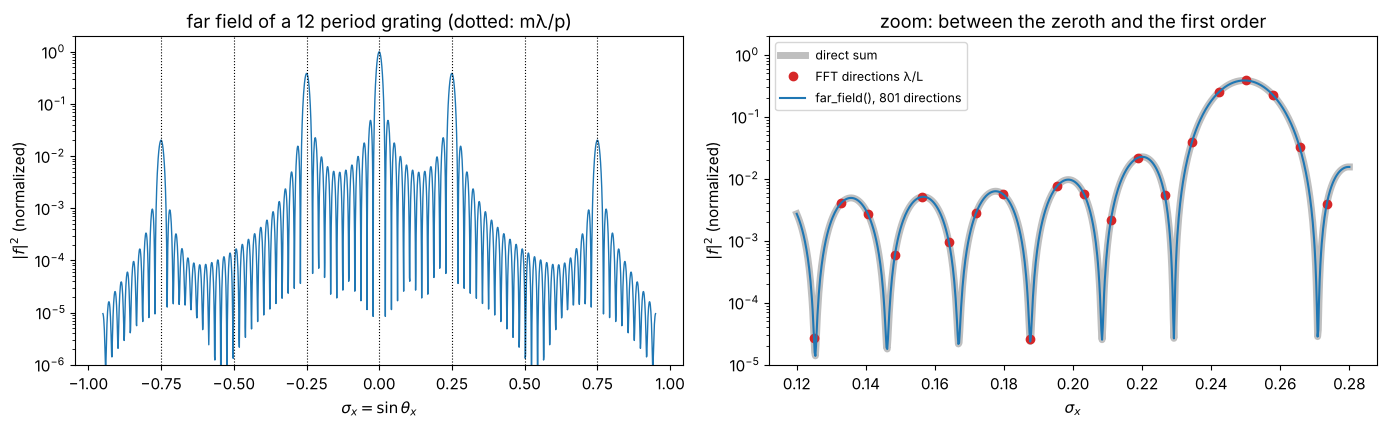

In [10]:
p, n_periods, duty = 4.0, 12, 0.5
L, N = 128.0, 1024
x = grid1d(-L/2, L/2, N)
X, Y = np.meshgrid(x, x)
grating = ((np.mod(X, p) < duty*p) & (np.abs(X) < n_periods*p/2) & (np.abs(Y) < 20)).astype(complex)

s_all = np.linspace(-0.95, 0.95, 1901)
f_all, _, _ = far_field(grating, x, x, WL, s_all, np.array([0.0]))
s_order = np.linspace(WL/p - 0.13, WL/p + 0.03, 801)
f_order, _, _ = far_field(grating, x, x, WL, s_order, np.array([0.0]))

# analytic: N-slit interference times the slit envelope; the open
# samples of the discrete grating are summed exactly
dx = x[1] - x[0]
row = grating[N//2]
open_x = x[np.abs(row) > 0]
n_y = np.count_nonzero(np.abs(grating[:, N//2 + 1]) > 0)
def analytic(s):
    s_z = np.sqrt(1 - s**2)
    A = np.exp(-1j*K*np.outer(s, open_x)).sum(axis=1)*dx*n_y*dx
    return K*s_z/(2j*np.pi)*A

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
I_max = np.abs(f_all).max()**2
axes[0].semilogy(s_all, np.abs(f_all[0])**2/I_max, "C0", lw=1)
for m in range(-3, 4):
    axes[0].axvline(m*WL/p, color="k", ls=":", lw=0.8)
axes[0].set_ylim(1E-6, 2)
axes[0].set_xlabel(r"$\sigma_x = \sin\theta_x$"); axes[0].set_ylabel(r"$|f|^2$ (normalized)")
axes[0].set_title("far field of a 12 period grating (dotted: mλ/p)")
axes[1].semilogy(s_order, np.abs(analytic(s_order))**2/I_max, color="0.75", lw=5, label="direct sum")
s_fft = frequencies(x)/K
in_zoom = (s_fft >= s_order[0]) & (s_fft <= s_order[-1])
f_fft = far_field(grating, x, x, WL, s_fft[in_zoom], np.array([0.0]))[0][0]
axes[1].semilogy(s_fft[in_zoom], np.abs(f_fft)**2/I_max, "o", color="C3", label="FFT directions λ/L")
axes[1].semilogy(s_order, np.abs(f_order[0])**2/I_max, "C0", label="far_field(), 801 directions")
axes[1].set_xlabel(r"$\sigma_x$"); axes[1].set_ylabel(r"$|f|^2$ (normalized)")
axes[1].set_title("zoom: between the zeroth and the first order")
axes[1].set_ylim(1E-5, 2); axes[1].legend(fontsize=9)
plt.tight_layout()
print("max deviation from the direct sum: {:.1e}".format(np.abs(f_order[0] - analytic(s_order)).max()/np.abs(f_order).max()))

## Summary

- `czt()` evaluates Fourier sums on any equidistant set of frequencies;
  `zoom_FT()` and `zoom_inv_FT()` wrap it with the pyoptics conventions and
  agree with `FT()`/`inv_FT()` (and with zero padded FFTs) to round-off.
- `get_psf(..., x_out, y_out)` resolves the PSF on any window without
  padding: the image grid only sets the pupil sampling.
- `fresnel_scaled()` and `fraunhofer_scaled()` free the output grid of the
  single-transform propagators; they agree with `fresnel_rescaling()` and
  `fraunhofer()` on those grids.
- `shifted_angular_spectrum()` propagates exactly onto off-axis and rescaled
  windows; padding to source + detector size together with the band limit
  removes the replicas.
- `far_field()` gives the far field in any set of directions, e.g. the fine
  structure of a single diffraction order.